# 05 · Toronto: video-pose quality & clinical scores

**Important finding for the project plan:** the Toronto videos are filmed walking *towards / away
from* the camera (frontal plane), and the released 2D pose has **no foot keypoints**
(COCO-17 lower body = hip/knee/ankle). It cannot serve directly as the sagittal video→pose bridge;
it is still useful as (a) a frontal-view pose-noise reference, and (b) Xsens-derived sagittal labels
with clinical scores (n = 11).

*This project is a prototype and is not medical advice.*

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from analysis import *
from canonical import J, JOINTS, SIDES
style()
pd.set_option("display.width", 200, "display.max_columns", 40)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


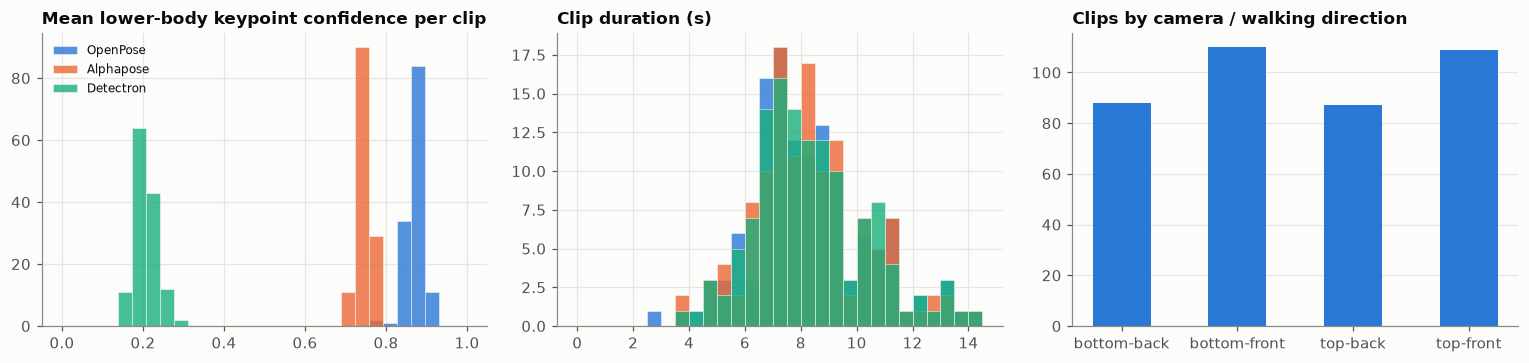

,n_frames,duration_s,mean_conf,frac_lowconf
estimator,,,,
Alphapose,246.523,8.716,0.749,0.000
Detectron,245.341,8.686,0.206,0.770
OpenPose,244.288,8.640,0.870,0.002


In [2]:
import load_toronto as LT
PC = pd.read_parquet(PROC / "toronto" / "pose_clips.parquet")
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
est = ["OpenPose", "Alphapose", "Detectron"]
for i, e in enumerate(est):
    g = PC[PC.estimator == e]
    axs[0].hist(g.mean_conf, bins=np.linspace(0, 1, 30), color=SERIES[i], alpha=0.8, label=e, edgecolor=SURFACE, linewidth=0.4)
    axs[1].hist(g.duration_s, bins=np.arange(0, 15, 0.5), color=SERIES[i], alpha=0.8, label=e, edgecolor=SURFACE, linewidth=0.4)
axs[0].set_title("Mean lower-body keypoint confidence per clip"); axs[0].legend(fontsize=8)
axs[1].set_title("Clip duration (s)")
ct = PC.groupby(["camera", "direction"]).size()
axs[2].bar([f"{c}-{d}" for c, d in ct.index], ct.values, color=SERIES[0], width=0.5)
axs[2].set_title("Clips by camera / walking direction"); axs[2].grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "05_pose_quality"); plt.show()
PC.groupby("estimator")[["n_frames", "duration_s", "mean_conf", "frac_lowconf"]].mean().round(3)

### One clip, three estimators (frontal view, image coordinates)

/tmp/nix-shell.SqEfpj/ipykernel_42760/726220277.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  pick = clips.set_index(key).loc[common].reset_index().sort_values("estimator", key=lambda e: e.map({"OpenPose": 0, "Alphapose": 1, "Detectron": 2}))


clip: {'pid': np.int64(1), 'camera': 'bottom', 'direction': 'back', 'clip': np.int64(1)}


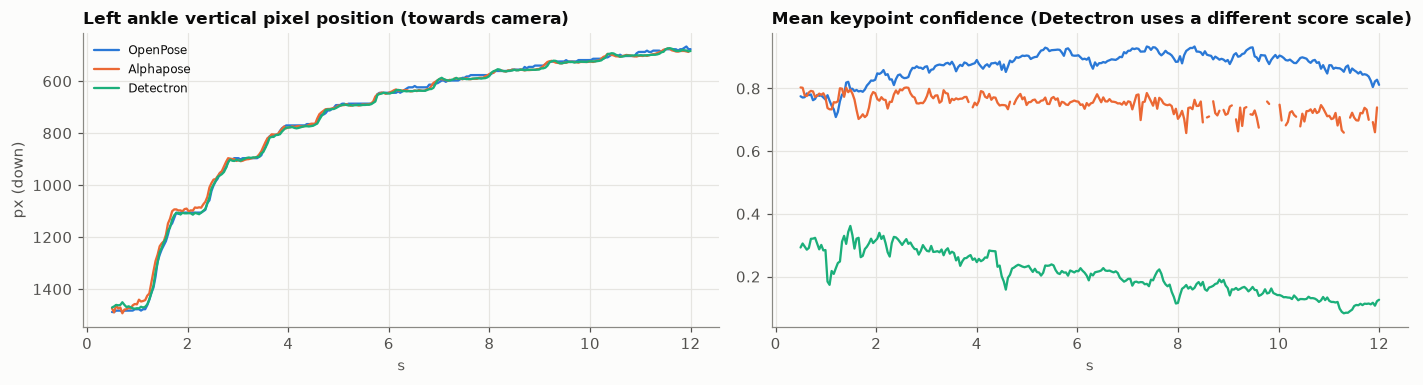

In [3]:
clips = LT.pose_clips()
key = ["pid", "camera", "direction", "clip"]
common = clips.groupby(key).estimator.nunique().loc[lambda n: n == 3].index[0]   # a clip all 3 estimators processed
pick = clips.set_index(key).loc[common].reset_index().sort_values("estimator", key=lambda e: e.map({"OpenPose": 0, "Alphapose": 1, "Detectron": 2}))
print("clip:", dict(zip(key, common)))
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
for i, r in enumerate(pick.itertuples()):
    p = LT.load_pose(r.path)
    a = p["xy"][:, LT.POSE_JOINTS.index("LAnkle"), 1]
    axs[0].plot(p["t"], a, color=SERIES[i], label=r.estimator, lw=1.5)
    axs[1].plot(p["t"], np.nanmean(p["conf"], 1), color=SERIES[i], label=r.estimator, lw=1.5)
axs[0].invert_yaxis(); axs[0].set_title("Left ankle vertical pixel position (towards camera)"); axs[0].set_xlabel("s"); axs[0].set_ylabel("px (down)")
axs[1].set_title("Mean keypoint confidence (Detectron uses a different score scale)"); axs[1].set_xlabel("s"); axs[0].legend(fontsize=8)
fig.tight_layout(); save(fig, "05_estimator_compare"); plt.show()

## Xsens-derived gait features vs clinical scores
Per-subject means over straight passes. n = 11 with a narrow, ceiling-limited score range —
read these as sanity checks, not findings (the original paper also found variability did not
track clinical scores).

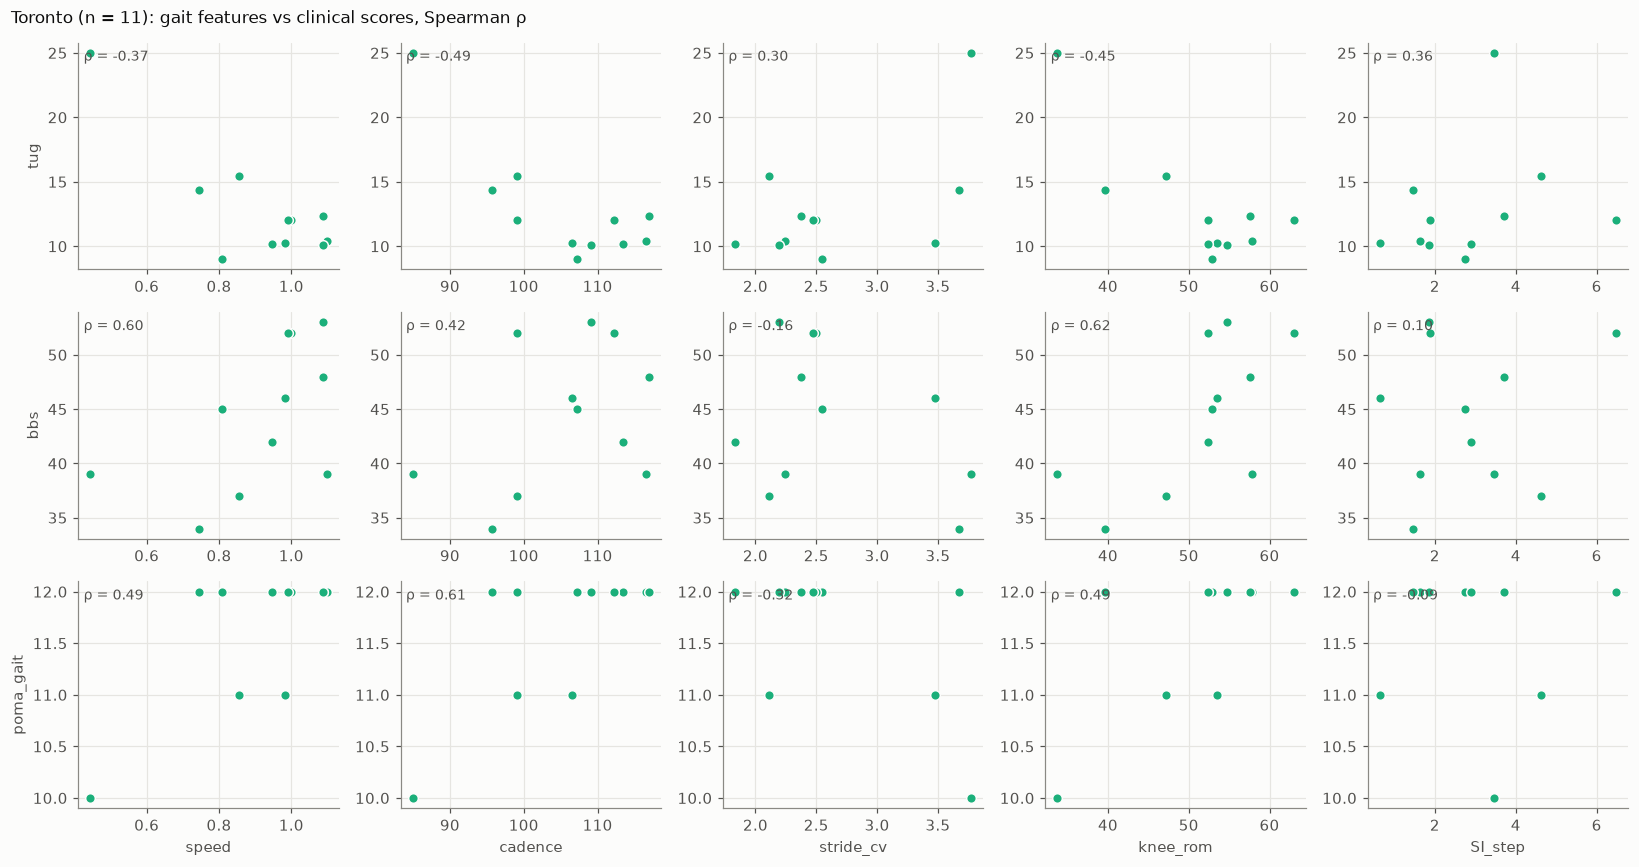

,speed,cadence,stride_cv,knee_rom,SI_step,tug,bbs,poma_gait,age
subject,,,,,,,,,
toronto_01,0.81,107.22,2.55,52.85,2.74,9.00,45.0,12.0,84.0
toronto_02,0.98,106.49,3.48,53.48,0.64,10.22,46.0,11.0,93.0
toronto_03,1.10,116.50,2.24,57.78,1.62,10.38,39.0,12.0,92.0
toronto_05,1.00,99.08,2.49,63.01,1.87,12.00,52.0,12.0,89.0
toronto_06,0.95,113.40,1.83,52.38,2.88,10.20,42.0,12.0,83.0
toronto_09,1.09,109.07,2.20,54.71,1.87,10.12,53.0,12.0,83.0
toronto_10,1.09,116.97,2.38,57.54,3.72,12.38,48.0,12.0,75.0
toronto_11,0.74,95.70,3.67,39.58,1.45,14.40,34.0,12.0,79.0
toronto_12,0.86,99.06,2.11,47.20,4.61,15.47,37.0,11.0,87.0


In [4]:
tor = trials("toronto", True)
P = tor.groupby("subject").agg(speed=("speed", "mean"), cadence=("cadence", "mean"), stride_cv=("stride_time_cv", "mean"),
                               knee_rom=("knee_rom", "mean"), SI_step=("SI_step_time", lambda s: s.abs().mean()),
                               tug=("tug_s", "first"), bbs=("bbs", "first"), poma_gait=("poma_gait", "first"), age=("age", "first"))
feats = ["speed", "cadence", "stride_cv", "knee_rom", "SI_step"]
scores = ["tug", "bbs", "poma_gait"]
fig, axs = plt.subplots(len(scores), len(feats), figsize=(15, 8))
for i, sc in enumerate(scores):
    for k, f in enumerate(feats):
        a = axs[i, k]
        a.scatter(P[f], P[sc], s=40, color=SERIES[2], edgecolor=SURFACE, linewidth=1)
        r = P[[f, sc]].corr(method="spearman").iloc[0, 1]
        a.text(0.02, 0.92, f"ρ = {r:.2f}", transform=a.transAxes, color=INK2, fontsize=9)
        if i == len(scores) - 1: a.set_xlabel(f)
        if k == 0: a.set_ylabel(sc)
fig.suptitle("Toronto (n = 11): gait features vs clinical scores, Spearman ρ", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); save(fig, "05_clinical_scatter"); plt.show()
P.round(2)

## Straight-pass segmentation
Overground hallway walking: turns are cut out (pelvis speed > 0.4 m/s and heading change < 0.6 rad/s,
0.5 s trimmed at each end, ≥ 4 s kept).

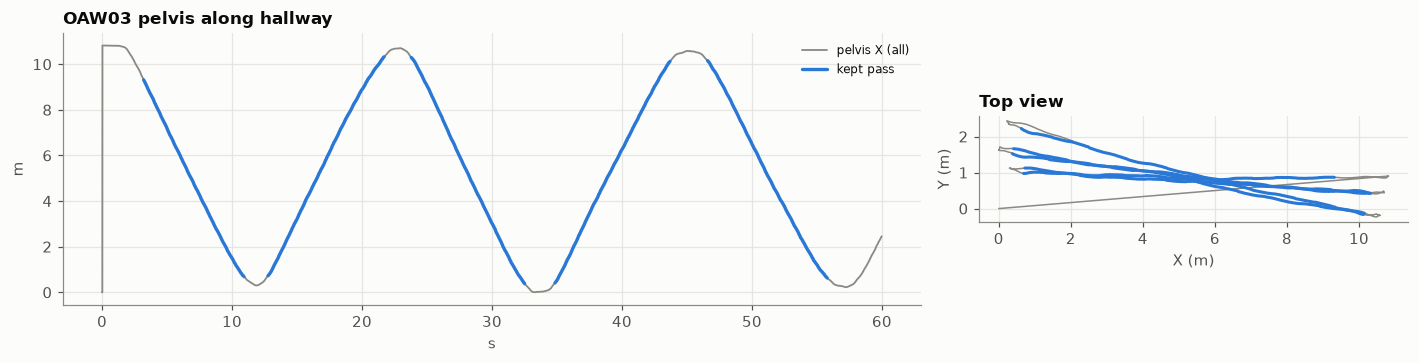

In [5]:
xyz = LT.load_xsens(3); ps = LT.split_passes(xyz)
p = xyz[:, J["pelvis"]]
fig, axs = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw=dict(width_ratios=[2, 1]))
t = np.arange(len(p)) / LT.FS
axs[0].plot(t, p[:, 0], color=MUTED, lw=1.2, label="pelvis X (all)")
for k, (s, e) in enumerate(ps):
    axs[0].plot(t[s:e], p[s:e, 0], color=SERIES[0], lw=2.2, label="kept pass" if k == 0 else None)
axs[0].set_xlabel("s"); axs[0].set_ylabel("m"); axs[0].set_title("OAW03 pelvis along hallway"); axs[0].legend(fontsize=8)
axs[1].plot(p[:, 0], p[:, 1], color=MUTED, lw=1)
for s, e in ps: axs[1].plot(p[s:e, 0], p[s:e, 1], color=SERIES[0], lw=2)
axs[1].set_aspect("equal"); axs[1].set_title("Top view"); axs[1].set_xlabel("X (m)"); axs[1].set_ylabel("Y (m)")
fig.tight_layout(); save(fig, "05_pass_segmentation"); plt.show()